In [7]:
from collections import Counter
from collections import defaultdict

# Base
import math
import os
from math import sqrt

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)

# Pattern Mining
from fim import (
    fpgrowth,
    apriori,
)

# Xmeans

from pyclustering.cluster import xmeans

In [37]:
df_primo = pd.read_csv('a_cmi_internet.csv')

df_17 = df_primo[df_primo['Basic_Demos-Age'] <= 17].copy()


''''FGC-FGC_GSND','FGC-FGC_GSD' sarebbero da non considerare per l'imputazione dei dati mancanti visto che sono presenti tantissimi 
missing values e la maggior parte dei valori sono tutti uguali:

Numero di volte in cui appare ogni valore nella colonna 'FGC-FGC_GSND':
FGC-FGC_GSND
20.05    1387
17.40     401
17.50     383
17.30     282
17.60     198

FGC-FGC_GSD
21.20    1390
18.75    1346
19.00     107
18.50      89
24.75      61
'''

colonna_da_analizzare = 'FGC-FGC_GSND'
colonna_da_analizzare2 = 'FGC-FGC_GSD'

conteggio_valori = df_17[colonna_da_analizzare].value_counts()
conteggio_valori2 = df_17[colonna_da_analizzare2].value_counts()

#print(conteggio_valori)
#print(conteggio_valori2)


'''i valori di 'CGAS-CGAS_Score' hanno un range ufficiale da 1-100 secondo 
https://www.corc.uk.net/outcome-measures-guidance/directory-of-outcome-measures/childrens-global-assessment-scale-cgas/

di conseguenza i valori oltre il 100 sono stati considerati come errori di inserimento e trattati quindi 
come valori mancanti'''

df_17["CGAS-CGAS_Score"] = df_17["CGAS-CGAS_Score"].mask(lambda x: x > 100, np.nan)

df_17['Fitness_Endurance-Tempo_totale']= df_17['Fitness_Endurance-Time_Sec']+(df_17['Fitness_Endurance-Time_Mins']*60)

'''considerando che in queste spcifiche colonne è impossibile che i valori siano pari a 0 (bmi,altezza e così via), gli 
zeri vengono considerati come valori mancanti e imputati. Per quanto riguarda i valori strani ma che non sono
zero, dato che non esiste un range ufficiale come per lo score, vengono trattati come outliers'''
#df_17['Physical-BMI', 'Physical-Weight', 'Physical-Diastolic_BP','Physical-Systolic_BP'] =



'considerando che in queste spcifiche colonne è impossibile che i valori siano pari a 0 (bmi,altezza e così via), gli \nzeri vengono considerati come valori mancanti e imputati. Per quanto riguarda i valori strani ma che non sono\nzero, dato che non esiste un range ufficiale come per lo score, vengono trattati come outliers'

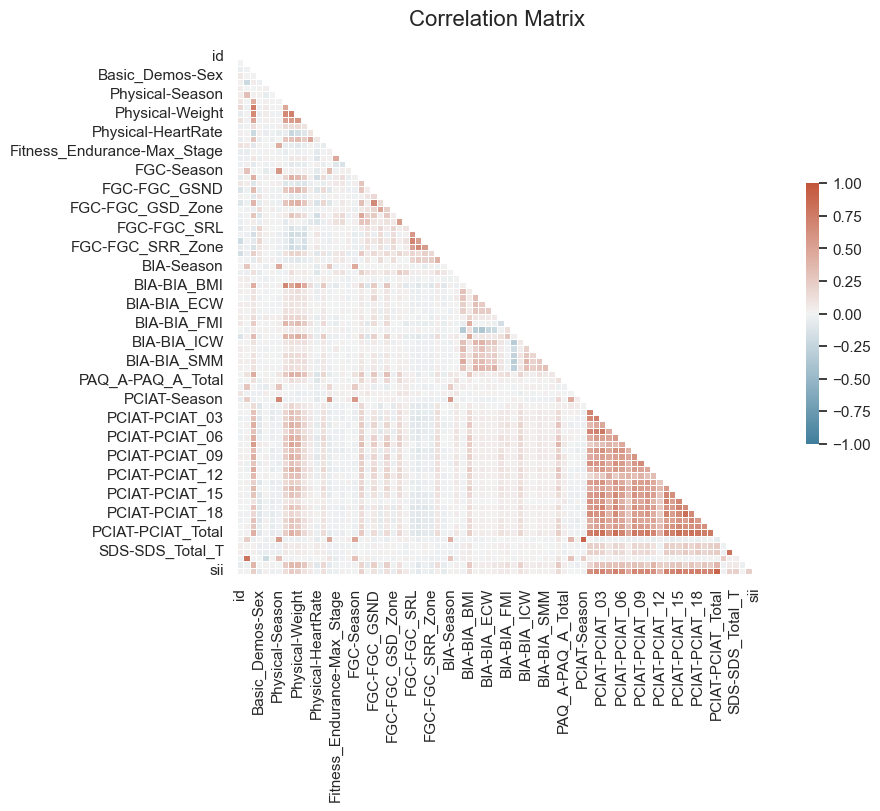

In [34]:
sns.set_theme(style="white")

def plot_professional_matrix(corr_matrix, title="Correlation Matrix"):
    # Creazione di una singola figura
    fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)

    # Maschera per nascondere la parte superiore (triangolo)
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    # Palette divergente professionale (es. Rosso-Blu)
    cmap = sns.diverging_palette(230, 20, as_cmap=True)

    # Generazione della heatmap
    sns.heatmap(corr_matrix,
                mask=mask,
                cmap=cmap,
                vmax=1, vmin=-1, center=0,
                square=True,
                linewidths=.5,
                cbar_kws={"shrink": .5},
                annot=False,             # Impostare a True per mostrare i numeri
                fmt=".2f",               # Formato arrotondamento decimali
                ax=ax)

    # Impostazione del titolo
    ax.set_title(title, fontsize=16, pad=20)

    plt.show()

plot_professional_matrix(correlazione)

In [16]:

colonne_selezionate = ['Physical-BMI', 'Physical-Height', 'Physical-Weight', 'Basic_Demos-Age']

aaa = df[colonne_selezionate].copy()

aaa['altezza_metri'] = aaa['Physical-Height'] * 0.0254
aaa['peso']= aaa['Physical-Weight']*0.453592

print(aaa)



      Physical-BMI  Physical-Height  Physical-Weight  Basic_Demos-Age  \
0        16.877316            46.00             50.8                5   
1        14.035590            48.00             46.0                9   
2        16.648696            56.50             75.6               10   
3        18.292347            56.00             81.6                9   
4        17.937682              NaN             77.0               18   
...            ...              ...              ...              ...   
8455     16.130585            46.07             49.0                7   
8456           NaN            56.13             47.8               10   
8457     40.937571            49.56             47.2               10   
8458           NaN            63.79             99.5               15   
8459     16.391310            51.46             43.7                7   

      altezza_metri       peso  
0          1.168400  23.042474  
1          1.219200  20.865232  
2          1.435100  34.